<a href="https://colab.research.google.com/github/IREStephen/ML-project-colab/blob/main/CampusDataSetProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Dataset Project

Stephen Duffy, 2026

## Data Preperation

This section loads the campus and prepares it for analysis.

In [1]:
import pandas as pd

## Load the Dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv(
    '/content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv',
    skiprows=4
)

## CSV Conversion

In [4]:
# Load the Excel file (corrected file path)
excel_path = '/content/drive/MyDrive/CampusWalkDataset.xlsx'
xls = pd.ExcelFile(excel_path)

# Print the sheet names to understand the structure
print("Sheets in Excel:", xls.sheet_names)

# Read the first sheet (or specify sheet_name if needed)
df_excel = pd.read_excel(excel_path, sheet_name=0)

# Export to CSV
csv_path = '/content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv'
df_excel.to_csv(csv_path, index=False)
print(f"Successfully converted and saved to: {csv_path}")

Sheets in Excel: ['Sheet1', 'Lists']
Successfully converted and saved to: /content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## Inspect the data structure...

In [5]:
print("Column Names\n")
print(df.dtypes)

print("\nSample Names")
print(df.head())

Column Names

recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature

## Label Encoder

## One-Hot Encoder

## Data Visualization: Comparing wellbeing_rate & stress_rating

I prompted Gemini to "Create a bar chart comparing wellbeing_rate and stress_rating" to compare human mood sets during the data gathering.
It gave an output of a well generated bar chart however the x axis values overlapped with eachother because of the width size of the chart. I did a small tweak with the value 8 and changed it to 12 in the plt.figure(figsize=(12, 6)) line.


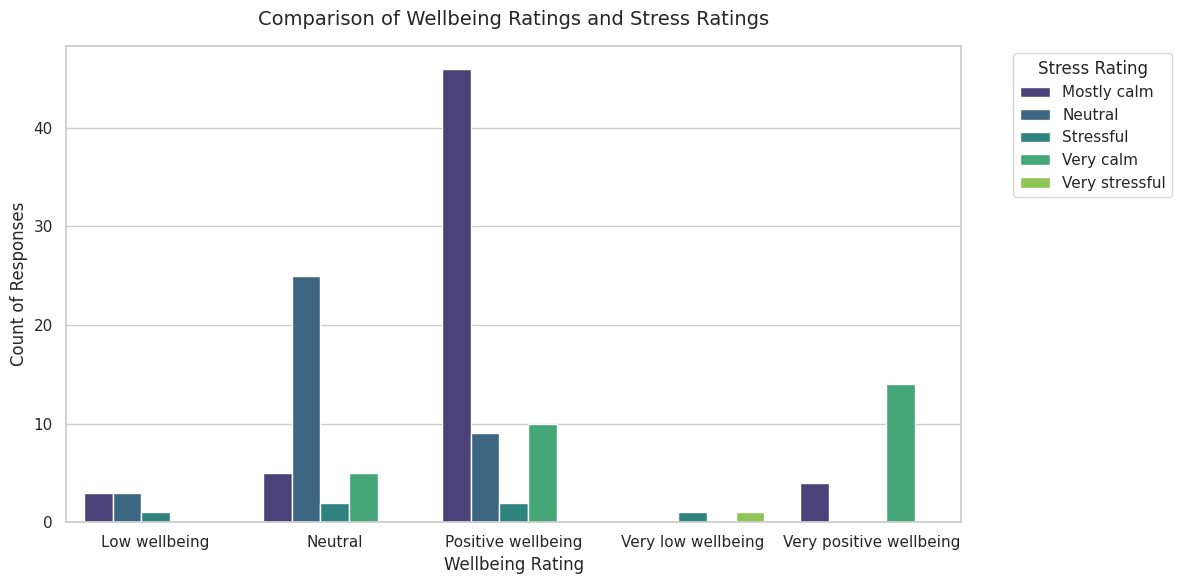

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group the cleaned data to compare wellbeing_rating and stress_rating
compare_df = clean_df.groupby(['wellbeing_rating', 'stress_rating']).size().reset_index(name='count')

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a grouped bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    data=compare_df,
    x='wellbeing_rating',
    y='count',
    hue='stress_rating',
    palette='viridis'
)

plt.title('Comparison of Wellbeing Ratings and Stress Ratings', fontsize=14, pad=15)
plt.xlabel('Wellbeing Rating', fontsize=12)
plt.ylabel('Count of Responses', fontsize=12)
plt.legend(title='Stress Rating', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Data Visualization: Table

In [8]:
import pandas as pd

# Load the CSV raw data
raw_df = pd.read_csv('/content/drive/MyDrive/CampusDatasetSyntheticDataExample.csv')

# The actual header is at row index 3 (the 4th row)
headers = raw_df.iloc[3].values

# Slice the data starting from index 4 to remove metadata and headers
clean_df = raw_df.iloc[4:].copy()

# Set correct column names
clean_df.columns = headers

# Reset the index
clean_df.reset_index(drop=True, inplace=True)

# Clean up column names by removing extra spaces
clean_df.columns = clean_df.columns.str.strip()

# Drop rows that are completely empty to keep valid data rows
clean_df.dropna(how='all', inplace=True)
clean_df.reset_index(drop=True, inplace=True)

# Brush up the data by filling specific missing categoricals with 'None' / 'Unknown'
fill_none_cols = [
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
    'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence', 'other_notes'
]
for col in fill_none_cols:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna('None')

# Standardize numeric columns
clean_df['temperature_c'] = pd.to_numeric(clean_df['temperature_c'], errors='coerce')
clean_df['insects_count'] = pd.to_numeric(clean_df['insects_count'], errors='coerce').fillna(0).astype(int)
clean_df['birds_count'] = pd.to_numeric(clean_df['birds_count'], errors='coerce').fillna(0).astype(int)

# Remove rows from index 134 down to 198
clean_df = clean_df.drop(clean_df.index[134:199])
clean_df.reset_index(drop=True, inplace=True)

# Configure Pandas to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Display updated shape and the entire dataframe
print(f"Brushed dataset shape: {clean_df.shape}")
display(clean_df)

Brushed dataset shape: (134, 23)


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,2026-09-22 00:00:00,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,2026-09-22 00:00:00,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,2026-09-22 00:00:00,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,2026-09-22 00:00:00,L01 MainEntrance,Sunny,17.0,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,2026-09-22 00:00:00,L04 PathFrontiHub,Windy,17.0,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,2026-09-22 00:00:00,L05 GreenFrontSportsCentre,Sunny,19.0,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,2026-09-22 00:00:00,L06 HedgingBehindSportsCentre,Cloudy,16.0,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,2026-09-22 00:00:00,L07 CarParkNearSportsCentre,Sunny,18.0,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


# Learning Process

The whole purpose of this was to do data cleaning. What I wanted to do with the data set is provide a table which stores the variables in an empty space along with it's respective header so everything is easier to visualise.

- I wanted to cut the empty cells after line 133.
- Have it where NaN or missing/unknown values get set to "None".
- Structured as a table.
- All the data transferred from the csv file to collab using python language.
- Learn the process and being able to articulate the code with the help of AI.

---

### 1. Dropping Empty Rows

To remove the cells where empty I used...

clean_df.dropna(how='all', inplace=True)
clean_df.reset_index(drop=True, inplace=True)

What does this do? so dropna(how='all') takes a look at my dataframe and removes all the empty cells.

reset_index(drop=True) this resets the (index) back to 0. (index) = numbers

inplace=True means that the changes can happen in my clean_df.

---

### 2. Cleaning or Filling Missing Text

fill_none_cols = [
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
    'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence', 'other_notes'
]
for col in fill_none_cols:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna('None')

This block of code lists columns that record text observes like types of sound or plants observed.
It loops back each column and uses this part called .fillna('None') to replace any empty cell with a 'None' string.

---

### 3. Standardizing the Numeric Columns

pd.to_numeric(['content'],errors='coerce') this codes purpose is to see what columns should have numbers in the cells and converts them from object or string to integers. Such as typos or symbols it just turns them into into an empty value which is now 'NaN' instead of giving errors.

.fillna(0) just replaces the empty field with 0.

.astype(int) makes sure that the insect and bird count are whole numbers so they cannot be floats and be 1.5 for example.

---

### 4. Trimming Specific Rows

clean_df = clean_df.drop(clean_df.index[134:199])
clean_df.reset_index(drop=True, inplace=True)

All this does is cut the rows from 134 to 199, then resets the index numbering again.

---

### 5. Config Display Options

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

These lines of code tells Pandas never to trim my table when visualising it as the table. This is because Pandas hides rows and columns with "..." if the dataset is too big to see.

So setting that to 'None' makes sure that Colab shows everysingle row in the output.